In [58]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


from utils_preproces import corr_heatmap_plot, make_mi_scores, preprocess_data
from sklearn.model_selection import train_test_split
from statsmodels.stats.outliers_influence import variance_inflation_factor


In [59]:
# Set Matplotlib defaults
plt.style.use("seaborn-v0_8-white")
plt.rc("figure", autolayout=True)
plt.rc(
    "axes",
    labelweight="bold",
    labelsize="large",
    titleweight="bold",
    titlesize=14,
    titlepad=10,
)

In [60]:
# Fix random state
random_state = 42

In [61]:
harps = pd.read_csv('harps_sample.csv')
apogee = pd.read_csv('apogee_sample.csv')
galah = pd.read_csv('galah_sample.csv')
gr8 = pd.read_csv('gr8_not_in_harps_sample.csv')

apogee = apogee[apogee.parallax > 0.]
galah = galah[(galah.parallax > 0.) ]

apogee['rel_parallax'] = apogee.parallax_error / apogee.parallax
apogee = apogee[apogee.rel_parallax < 0.1]

galah['rel_parallax'] = galah.parallax_error / galah.parallax
galah = galah[galah.rel_parallax < 0.1]


harps['rel_parallax'] = harps.parallax_error / harps.parallax
harps = harps[harps.rel_parallax < 0.1]

# Seelcting only giants
apogee = apogee[apogee.logg < 3]

# Selecting only dwarfs
galah = galah[galah.logg > 3]


print (f'harps contains {len(harps)} stars')
print (f'apogee contains {len(apogee)} stars')    
print (f'galah contains {len(galah)} stars')
print (f'gr8 contains {len(gr8)} stars')

harps contains 798 stars
apogee contains 45812 stars
galah contains 71591 stars
gr8 contains 1430 stars


# Here we focus on getting Fe from no abundance

In [62]:
columns_for_Fe = ['U_lsr', 'V_lsr', 'W_lsr', 'P_gal', 
       'rapo', 'rperi', 'eccentricity', 'zmax', 
       'fe_h', ]

# excluded Tp and radial_velocity, because when training on apogee and testing on harps, the dependence of feh on these parameters for the two samples have different signs. 
# excluded 'Ez',  'Lz',  'Or', 'Oz', 'Tz', 'jp', 'jr', 'jz',
apogee = apogee[columns_for_Fe]
harps = harps[columns_for_Fe]
galah = galah[columns_for_Fe]
gr8 = gr8[columns_for_Fe]

In [63]:
def fit_trasform(X):
    X['VW_lsr'] = np.sqrt(X['V_lsr']**2 + X['W_lsr']**2)
    X['UW_lsr'] = np.sqrt(X['U_lsr']**2 + X['W_lsr']**2)
    X['UV_lsr'] = np.sqrt(X['U_lsr']**2 + X['V_lsr']**2)
    X['UVW_lsr'] = np.sqrt(X['U_lsr']**2 + X['V_lsr']**2 + X['W_lsr']**2)
    epsilon = 1e-6
    #log features
    #X['Log_RV'] = np.log(X['RV'] + np.abs(X['RV'].min()))
    #X['Log_U_lsr'] = np.log(X['U_lsr'] + np.abs(X['U_lsr'].min()) + epsilon)
    #X['Log_V_lsr'] = np.log(X['V_lsr'] + np.abs(X['V_lsr'].min()) + epsilon)
    X['abs_W_lsr'] =np.abs(X['W_lsr'])
    X['abs_U_lsr'] =np.abs(X['U_lsr'])
    #X['Log_UW_lsr'] = np.log(X['UW_lsr'])
    #X['Log_UVW_lsr'] = np.log(X['UVW_lsr'])
    #X.drop(columns = ['U_lsr', 'W_lsr'], inplace = True)
    X['R_mean'] = (X['rapo'] + X['rperi'])/2
    #X.drop(columns = ['rperi', 'rapo'], inplace = True)

    return X

apogee = fit_trasform(apogee)
harps = fit_trasform(harps)
galah = fit_trasform(galah)
gr8 = fit_trasform(gr8)

In [64]:
# Define pretty labels once
PRETTY_LABELS = {
    "U_lsr":        r"$U_{\mathrm{LSR}}\, [km/s]$",
    "V_lsr":        r"$V_{\mathrm{LSR}}\, [km/s]$",
    "W_lsr":        r"$W_{\mathrm{LSR}}\, [km/s]$",
    "UV_lsr":       r"$UV_{\mathrm{LSR}}\, [km/s]$",
    "UW_lsr":       r"$UW_{\mathrm{LSR}}\, [km/s]$",
    "VW_lsr":       r"$VW_{\mathrm{LSR}}\, [km/s]$ ",
    "UVW_lsr":      r"$UVW_{\mathrm{LSR}}\, [km/s]$",
    "abs_U_lsr":    r"$|U|_{\mathrm{LSR}}\, [km/s]$",
    "abs_W_lsr":    r"$|W|_{\mathrm{LSR}}\, [km/s]$",
    "P_gal":        r"$P_{\mathrm{gal}}\, [\%]$",
    "rapo":         r"$R_{\mathrm{apo}}\, [Kpc]$",
    "rperi":        r"$R_{\mathrm{peri}}\, [Kpc]$",
    "zmax":         r"$Z_{\max}\, [Kpc]$",
    "eccentricity": r"$e$",
    "R_mean":       r"$R_{\mathrm{mean}}\, [Kpc]$",
}

### Identifying and exluding null values

In [65]:
apogee.isnull().sum() # 196 null value for P_gal
apogee.dropna(inplace = True)

In [66]:
galah.isnull().sum() # 1 null value for P_gal
galah.dropna(inplace = True)

In [67]:
#gr8.isnull().sum() # No null values

In [68]:
#harps.isnull().sum() # No null values

### excluding outliers from apogee

In [69]:
#apogee = apogee[(apogee.zmax < 10) & (apogee.jz < 300) & (apogee.Tz < 0.3) & (apogee.Ez < 10000) & (apogee.jr < 3000) & (apogee.abs_W_lsr < 200) & (apogee.rapo.between(7, 20)) & (apogee.rperi.between(0, 9))]
apogee_copy = apogee[(apogee.zmax < 10)  & (apogee.abs_W_lsr < 200) ]
apogee_copy.shape

(45726, 16)

In [70]:
apogee = apogee_copy[apogee_copy.zmax < 50]
apogee.shape

(45726, 16)

### Spliting data into Trianing and Testing sets

In [71]:
# Split APOGEE
apogee_train_full, apogee_test = train_test_split(apogee, test_size=0.1, random_state=random_state)
X_apogee = apogee_train_full.drop(columns=['fe_h'])
y_apogee = apogee_train_full['fe_h']
X_apogee_train = apogee_train_full.drop(columns=['fe_h'])
y_apogee_train = apogee_train_full['fe_h']

X_apogee_test = apogee_test.drop(columns=['fe_h'])
y_apogee_test = apogee_test['fe_h']

# Split GALAH
galah_train_full, galah_test = train_test_split(galah, test_size=0.3, random_state=random_state)
X_galah = galah_train_full.drop(columns=['fe_h'])
y_galah = galah_train_full['fe_h']
X_galah_train = galah_train_full.drop(columns=['fe_h'])
y_galah_train = galah_train_full['fe_h']

X_galah_test = galah_test.drop(columns=['fe_h'])
y_galah_test = galah_test['fe_h']

# Gr8 no split
X_gr8 = gr8.drop(columns=['fe_h'])
y_gr8 = gr8['fe_h']

# HARPS — no split
X_harps = harps.drop(columns=['fe_h'])
y_harps = harps['fe_h']

# Combine APOGEE and GALAH train sets
X_combined_train = pd.concat([X_apogee_train, X_galah_train], ignore_index=True)
y_combined_train = pd.concat([y_apogee_train, y_galah_train], ignore_index=True)


full_df = pd.concat([apogee,   harps], ignore_index=True)
X_full = full_df.drop(columns=['fe_h'])
y_full = full_df['fe_h']

In [72]:
def feature_target_correlation(df, target):
    corr = df.corr(numeric_only=True, method='spearman',)[target].drop(target).sort_values(key=abs, ascending=False)
    return corr
correlations = feature_target_correlation(df=X_full.assign(fe_h=y_full), target='fe_h')
correlations


zmax           -0.511036
P_gal           0.275914
abs_W_lsr      -0.260265
VW_lsr         -0.251376
eccentricity   -0.227528
UVW_lsr        -0.225535
rapo           -0.209574
UV_lsr         -0.173580
UW_lsr         -0.165197
V_lsr           0.132597
R_mean         -0.100685
abs_U_lsr      -0.068512
W_lsr          -0.024741
U_lsr          -0.003463
rperi           0.002648
Name: fe_h, dtype: float64

/tmp/ipykernel_17616/522446026.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=correlations.values, y=correlations.index, palette="viridis")


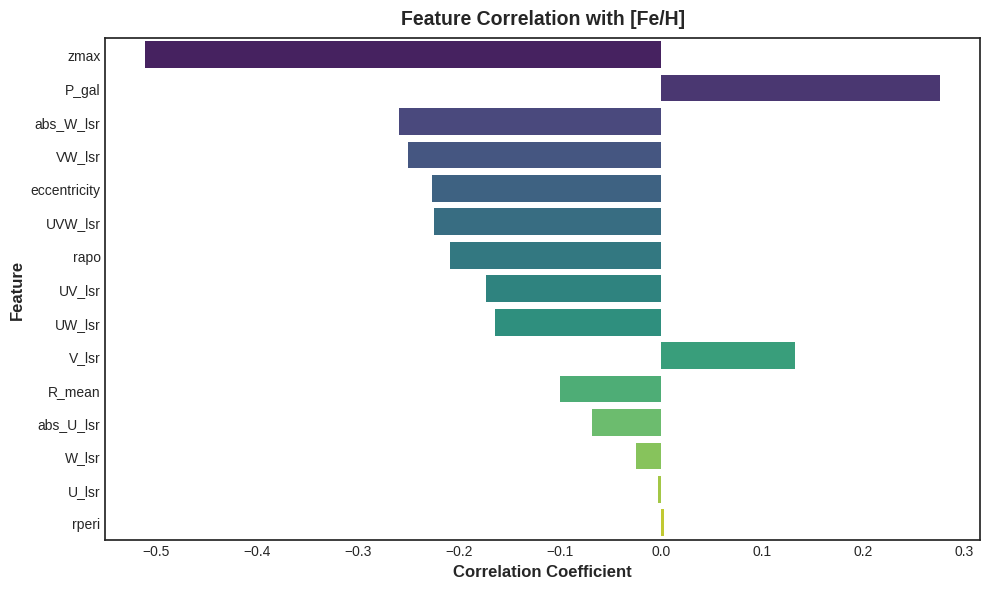

In [73]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
sns.barplot(x=correlations.values, y=correlations.index, palette="viridis")
plt.title('Feature Correlation with [Fe/H]')
plt.xlabel('Correlation Coefficient')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()


pandas-profiling (now renamed to ydata-profiling)
✅ What it gives:
Target correlation heatmaps

Distribution plots of features

Missing value analysis

Duplicates detection

Interaction matrices

Report export (HTML, JSON)

In [74]:
from ydata_profiling import ProfileReport
#profile = ProfileReport(X_harps.assign(fe_h=y_harps), title="EDA Report", explorative=True)
#profile.to_file("eda_report.html")  # Opens in your browser


In [75]:
import sweetviz as sv

#report = sv.analyze([harps, "Train"], target_feat="fe_h")
#report.show_html("sweetviz_report.html")


In [76]:
#sv.compare([X_combined_train.assign(fe_h=y_combined_train), "Train"], [harps, "Test"]).show_html("compare.html")


In [77]:
from sklearn.feature_selection import mutual_info_regression
import numpy as np
import pandas as pd

def select_features_by_mi_and_correlation(X, y, corr_thresh=0.9, top_n=None, verbose=True):
    # 1. Compute mutual information
    mi = mutual_info_regression(X, y)
    mi_df = pd.DataFrame({'Feature': X.columns, 'MI': mi}).sort_values(by='MI', ascending=False)

    selected = []
    removed = []
    remaining = list(mi_df['Feature'])

    while remaining:
        # Pick the highest MI feature
        best = remaining.pop(0)
        selected.append(best)

        if verbose:
            print(f"Selected: {best} (MI={mi_df.set_index('Feature').loc[best, 'MI']:.4f})")

        # Remove features highly correlated with 'best'
        to_remove = []
        for feature in remaining:
            corr = np.corrcoef(X[best], X[feature])[0, 1]
            if abs(corr) > corr_thresh:
                to_remove.append(feature)

        for f in to_remove:
            remaining.remove(f)
            removed.append(f)
            if verbose:
                print(f"  Removed due to high correlation with {best}: {f} (|corr|={abs(np.corrcoef(X[best], X[f])[0, 1]):.2f})")

        # Stop if top_n features are selected
        if top_n and len(selected) >= top_n:
            break

    return selected, removed



In [78]:
selected_features_full, removed_features_full = select_features_by_mi_and_correlation(X_full, y_full, corr_thresh=0.999)
print("Selected:", selected_features_full)

Selected: zmax (MI=0.1776)
Selected: rperi (MI=0.1228)
Selected: R_mean (MI=0.0996)
Selected: VW_lsr (MI=0.0874)
Selected: P_gal (MI=0.0858)
Selected: eccentricity (MI=0.0775)
Selected: rapo (MI=0.0758)
Selected: V_lsr (MI=0.0713)
Selected: abs_W_lsr (MI=0.0687)
Selected: W_lsr (MI=0.0613)
Selected: UVW_lsr (MI=0.0528)
Selected: UV_lsr (MI=0.0407)
Selected: UW_lsr (MI=0.0231)
Selected: abs_U_lsr (MI=0.0048)
Selected: U_lsr (MI=0.0024)
Selected: ['zmax', 'rperi', 'R_mean', 'VW_lsr', 'P_gal', 'eccentricity', 'rapo', 'V_lsr', 'abs_W_lsr', 'W_lsr', 'UVW_lsr', 'UV_lsr', 'UW_lsr', 'abs_U_lsr', 'U_lsr']


First 15 of 15 features:
zmax            0.177625
rperi           0.123480
R_mean          0.099446
P_gal           0.086942
VW_lsr          0.086747
eccentricity    0.076940
rapo            0.075821
V_lsr           0.071332
abs_W_lsr       0.068799
W_lsr           0.061768
UVW_lsr         0.052224
UV_lsr          0.040777
UW_lsr          0.023263
abs_U_lsr       0.005556
U_lsr           0.002269
Name: MI Scores, dtype: float64


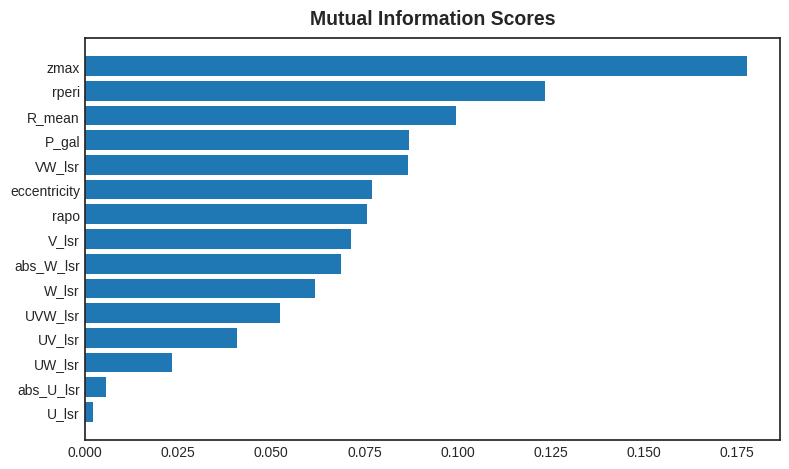

In [79]:
mi_scores_full = make_mi_scores(X_full, y=y_full,  plot = True)

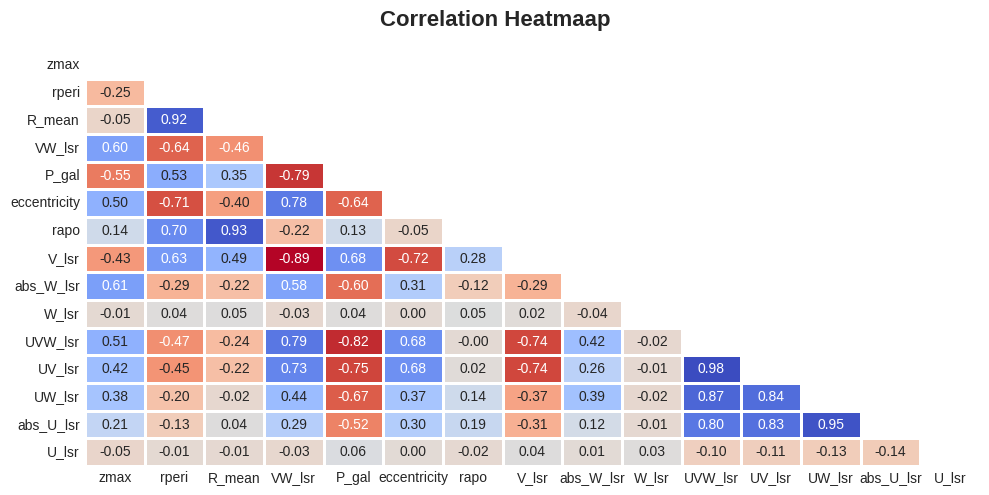

In [80]:
# Displays the correlation hitmap
corr_heatmap_plot(X_full[selected_features_full])

In [81]:
from statsmodels.tools.tools import add_constant
import numpy as np

X_new = X_full[selected_features_full].copy()
X_new = add_constant(X_new)

vif_data = []
for i in range(X_new.shape[1]):
    try:
        vif_value = variance_inflation_factor(X_new.values, i)
    except Exception as e:
        vif_value = np.inf
        print(f"Failed VIF for {X_new.columns[i]}: {e}")
    vif_data.append((X_new.columns[i], vif_value))

vif_df = pd.DataFrame(vif_data, columns=['Variable', 'VIF'])
print(vif_df[vif_df['VIF'] > 0])  # or any threshold you like



/home/vadibekyan/anaconda3/lib/python3.12/site-packages/statsmodels/stats/outliers_influence.py:197: RuntimeWarning: divide by zero encountered in scalar divide
  vif = 1. / (1. - r_squared_i)


        Variable         VIF
0          const   96.506236
1           zmax    2.242218
2          rperi         inf
3         R_mean         inf
4         VW_lsr   41.095439
5          P_gal    4.589919
6   eccentricity   16.919810
7           rapo         inf
8          V_lsr    9.162920
9      abs_W_lsr    9.214642
10         W_lsr    1.007947
11       UVW_lsr  540.360820
12        UV_lsr  319.360770
13        UW_lsr  187.827340
14     abs_U_lsr  105.387240
15         U_lsr    1.030402


In [82]:
X_new_low_VIF = X_full[selected_features_full].copy()
X_new_low_VIF = X_new_low_VIF.drop(columns=['UVW_lsr'])
X_new_low_VIF = add_constant(X_new_low_VIF)

vif_data = []
for i in range(X_new_low_VIF.shape[1]):
    try:
        vif_value = variance_inflation_factor(X_new_low_VIF.values, i)
    except Exception as e:
        vif_value = np.inf
        print(f"Failed VIF for {X_new_low_VIF.columns[i]}: {e}")
    vif_data.append((X_new_low_VIF.columns[i], vif_value))

low_vif_df = pd.DataFrame(vif_data, columns=['Variable', 'VIF'])
print(low_vif_df[low_vif_df['VIF'] > 0])  # or any threshold you like

/home/vadibekyan/anaconda3/lib/python3.12/site-packages/statsmodels/stats/outliers_influence.py:197: RuntimeWarning: divide by zero encountered in scalar divide
  vif = 1. / (1. - r_squared_i)


        Variable        VIF
0          const  96.503312
1           zmax   2.234936
2          rperi        inf
3         R_mean        inf
4         VW_lsr  25.397228
5          P_gal   4.559549
6   eccentricity  16.818417
7           rapo        inf
8          V_lsr   8.698905
9      abs_W_lsr   9.101794
10         W_lsr   1.006713
11        UV_lsr  45.686450
12        UW_lsr  64.777224
13     abs_U_lsr  60.978749
14         U_lsr   1.030379


In [83]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold
import numpy as np
import time

def model_test_CV_models(X, y, models, k=5, random_state=42):
    """
    Perform k-fold cross-validation for multiple models.
    Returns mean and std of RMSE, MAE, and R2.
    """
    kf = KFold(n_splits=k, shuffle=True, random_state=random_state)
    results = {}

    for name, model in models.items():
        print(f"Scoring model: {name}")
        start_time = time.time()

        rmse_scores = []
        mae_scores = []
        r2_scores = []

        for train_index, test_index in kf.split(X, y):
            X_train, X_test = X.iloc[train_index], X.iloc[test_index]
            y_train, y_test = y.iloc[train_index], y.iloc[test_index]

            model.fit(X_train, y_train)
            y_pred = model.predict(X_test)

            rmse = np.sqrt(mean_squared_error(y_test, y_pred))
            mae = mean_absolute_error(y_test, y_pred)
            r2 = r2_score(y_test, y_pred)

            rmse_scores.append(rmse)
            mae_scores.append(mae)
            r2_scores.append(r2)

        elapsed_time = time.time() - start_time

        results[name] = {
            'mean_rmse': np.mean(rmse_scores),
            'std_rmse': np.std(rmse_scores),
            'mean_mae': np.mean(mae_scores),
            'mean_r2': np.mean(r2_scores),
            'time_sec': elapsed_time
        }

        print(
            f"{name} → "
            f"RMSE: {results[name]['mean_rmse']:.3f} ± {results[name]['std_rmse']:.3f} | "
            f"MAE: {results[name]['mean_mae']:.3f} | "
            f"R²: {results[name]['mean_r2']:.3f} "
            f"({elapsed_time:.2f}s)\n"
        )

    return results

In [84]:
best_features = [x for x in selected_features_full if x not in []]

In [85]:
apogee_final_for_feh = apogee[[*best_features,'fe_h']]
apogee_final_for_feh.to_csv('apogee_final_for_feh.csv', index=False)

galah_final_for_feh = galah[[*best_features,'fe_h']]
galah_final_for_feh.to_csv('galah_final_for_feh.csv', index=False)

harps_final_for_feh = harps[[*best_features,'fe_h']]
harps_final_for_feh.to_csv('harps_final_for_feh.csv', index=False)